# Phase 1 - Convolutional Neural Networks

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.

## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [1]:
# Run to import necessary libraries
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [2]:
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor()) # creates MNIST training set

test_data = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor()) #same for 10000 image test split

batch_size = 32

train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True) #batches training set

test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False) #batches test set

In [3]:
# Function should input the dataloader, and show random 10 images and their labels as title to plot
def show_imgs():
    images, labels = next(iter(train_loader)) # starts iterator over loader and creates a figure 12 inches wide and tall
    plt.figure(figsize=(12, 3))
    for i in range(10):
        plt.subplot(2, 5, i + 1) #selects panel i+1 in grid of 2 rowsand 5 columns
        plt.imshow(images[i].squeeze(), cmap='gray') #draws image and removes size-1 channel, displaying in grayscale
        plt.title(f'Label: {labels[i].item()}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [4]:
def test_accuracy(model, test_loader, input_size, device):
    model.to(device)
    correct = 0
    total = 0
    with torch.no_grad(): #gradient tracking off
        for test_data in test_loader:
            images, labels = test_data[0].cuda(), test_data[1].cuda() #splits batch into images and labels and move both to GPU
            images = images.view(-1, input_size) #flattens 28x28 to 784 number vector
            outputs = net(images)
            _, predicted = torch.max(outputs.data, 1) #takes highest-scoring class for each image
            total += labels.size(0)
            correct += (predicted == labels).sum().item() #adds batch size to total ands # of correct predictions to correct
    print('Accuracy: %d %%' % (100 * correct / total))


## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [5]:
def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device):
    import time
    global train_losses, train_accs, test_losses, test_accs 
    model.to(device)
    test_accuracy.__defaults__ = (device,)
    if device.type == 'cpu': #sets default value of test_accuracy's last paramter to device
        torch.Tensor.cuda = lambda self, *a, **k: self  #for CPU only machine, makes it so test_accuracy's .cuda doesn't crash
    train_losses, train_accs = [], []  
    test_losses, test_accs = [], []   

    flatten = isinstance(next(model.children()), nn.Linear) #looks at model's first layer, bc model is MLP, flatten=true. If CNN has conv layer, flatten=false

    for epoch in range(num_epochs):
        start = time.time()

        model.train()
        run_loss, run_correct, run_total = 0.0, 0, 0 
        for images, labels in train_loader: #loops over batches and moves thme to device, flatten if model is MLP
            images, labels = images.to(device), labels.to(device)
            if flatten:
                images = images.view(images.size(0), -1)

            optimizer.zero_grad() #training steps
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            correct = (outputs.argmax(1) == labels).sum().item() #counts correct predictions and appends to batch's loss
            train_losses.append(loss.item())
            train_accs.append(100 * correct / labels.size(0))

            run_loss += loss.item() * labels.size(0) #accumulate epoch totals
            run_correct += correct
            run_total += labels.size(0)

        epoch_train_loss = run_loss / run_total #avg training loss and accuracy
        epoch_train_acc = 100 * run_correct / run_total

        model.eval() #switches to evaluation mode and turns off gradients, runs flatten and forward steps
        t_loss, t_correct, t_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                if flatten:
                    images = images.view(images.size(0), -1)
                outputs = model(images)
                t_loss += loss_fn(outputs, labels).item() * labels.size(0)
                t_correct += (outputs.argmax(1) == labels).sum().item()
                t_total += labels.size(0)

        epoch_test_loss = t_loss / t_total #computes epcoh test loss and accuracy and appends to history
        epoch_test_acc = 100 * t_correct / t_total
        test_losses.append(epoch_test_loss)
        test_accs.append(epoch_test_acc)

        print(f'Epoch {epoch+1}/{num_epochs} | ' #print results
              f'Train loss: {epoch_train_loss:.4f}, acc: {epoch_train_acc:.2f}% | '
              f'Test loss: {epoch_test_loss:.4f}, acc: {epoch_test_acc:.2f}% | '
              f'Time: {time.time() - start:.1f}s')

    return train_losses, train_accs, test_losses, test_accs

## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [6]:
def plot_learning_curve(train_losses, train_accs, test_losses, test_accs):
    num_epochs = len(test_losses) 
    iters_per_epoch = len(train_losses) // num_epochs #calculates total # of batches
    train_x = np.arange(1, len(train_losses) + 1) / iters_per_epoch # builds x-coordinates of graphs
    test_x = np.arange(1, num_epochs + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1) #selects first panel of 1 row 2 column grid
    plt.plot(train_x, train_losses, label='Train', alpha=0.6) #draws noisy per-iteration train curve, semi-transparent(alpha=0.6) so it doens't hide test line
    plt.plot(test_x, test_losses, 'o-', label='Test')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Loss') #axes label and titling
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(train_x, train_accs, label='Train', alpha=0.6)
    plt.plot(test_x, test_accs, 'o-', label='Test')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)'); plt.title('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [7]:
class Net(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net,self).__init__()
        self.fc1 = nn.Linear(input_size, 500)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(500, num_classes)

    def forward(self,x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [8]:
# Define 2-Layer Network
class Net2(nn.Module):
    def __init__(self, input_size=1, num_classes=10):
        super(Net2, self).__init__()
        self.conv1 = nn.Conv2d(1, 20, kernel_size=3, stride=1) #convolution with 1 input channel, 20 output, and stride 1
        self.relu = nn.ReLU() #negative values=0
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes) #fully connected layer from flattened feature maps

    def forward(self, x):
        x = x.view(-1, 1, 28, 28) #reshapes input to batch, 1, 28, 28. 
        out = self.conv1(x) #apply filters, then ReLU
        out = self.relu(out)
        out = out.view(out.size(0), -1) #flattens each image's features maps into a single vector, then maps to 10 raw scores
        out = self.fc1(out)
        return out

# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

Epoch 1/10 | Train loss: 0.2493, acc: 92.91% | Test loss: 0.1998, acc: 94.84% | Time: 8.1s
Epoch 2/10 | Train loss: 0.1678, acc: 95.48% | Test loss: 0.1631, acc: 95.90% | Time: 7.7s
Epoch 3/10 | Train loss: 0.1420, acc: 96.30% | Test loss: 0.1702, acc: 96.20% | Time: 8.0s
Epoch 4/10 | Train loss: 0.1339, acc: 96.67% | Test loss: 0.1920, acc: 95.99% | Time: 7.6s
Epoch 5/10 | Train loss: 0.1186, acc: 97.10% | Test loss: 0.1984, acc: 96.31% | Time: 7.6s
Epoch 6/10 | Train loss: 0.1153, acc: 97.14% | Test loss: 0.1921, acc: 96.48% | Time: 7.7s
Epoch 7/10 | Train loss: 0.1150, acc: 97.29% | Test loss: 0.2606, acc: 95.99% | Time: 7.6s
Epoch 8/10 | Train loss: 0.1124, acc: 97.56% | Test loss: 0.2356, acc: 96.59% | Time: 7.7s
Epoch 9/10 | Train loss: 0.1061, acc: 97.63% | Test loss: 0.2283, acc: 96.53% | Time: 7.7s
Epoch 10/10 | Train loss: 0.0968, acc: 97.86% | Test loss: 0.2574, acc: 96.47% | Time: 8.0s


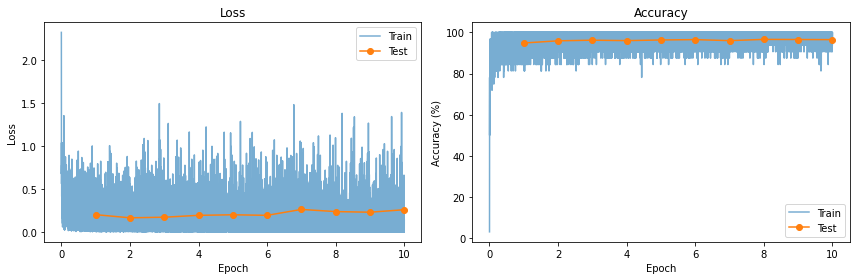

Accuracy: 96 %


In [9]:
# Define Parameters
input_size = 28*28 #size 784
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #pick GPU if exists, if not uses CPU
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss() #multi-class loss
optimizer = torch.optim.Adam(net.parameters(), lr=lr) #adam updates all model's weights

# Train Model
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

Epoch 1/10 | Train loss: 0.2139, acc: 95.05% | Test loss: 0.0839, acc: 97.38% | Time: 5.4s
Epoch 2/10 | Train loss: 0.0762, acc: 97.73% | Test loss: 0.0767, acc: 97.71% | Time: 5.5s
Epoch 3/10 | Train loss: 0.0543, acc: 98.28% | Test loss: 0.0763, acc: 97.81% | Time: 5.5s
Epoch 4/10 | Train loss: 0.0426, acc: 98.69% | Test loss: 0.1148, acc: 97.40% | Time: 5.5s
Epoch 5/10 | Train loss: 0.0378, acc: 98.81% | Test loss: 0.1237, acc: 97.64% | Time: 5.6s
Epoch 6/10 | Train loss: 0.0280, acc: 99.14% | Test loss: 0.1382, acc: 97.76% | Time: 5.6s
Epoch 7/10 | Train loss: 0.0233, acc: 99.29% | Test loss: 0.1388, acc: 97.74% | Time: 5.7s
Epoch 8/10 | Train loss: 0.0211, acc: 99.41% | Test loss: 0.1602, acc: 97.90% | Time: 5.9s
Epoch 9/10 | Train loss: 0.0218, acc: 99.40% | Test loss: 0.1831, acc: 97.66% | Time: 6.2s
Epoch 10/10 | Train loss: 0.0169, acc: 99.51% | Test loss: 0.1803, acc: 97.82% | Time: 6.3s


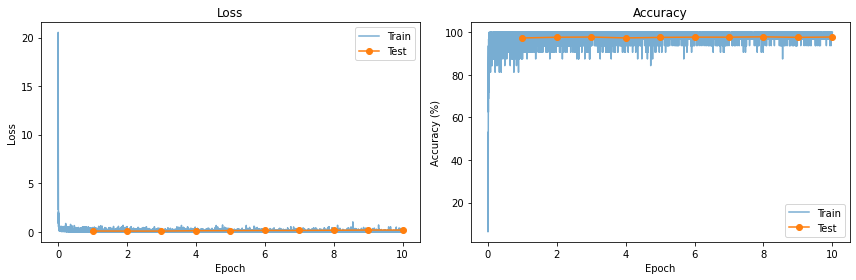

Accuracy: 97 %


In [10]:
# Define Parameters
input_size = 28*28
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net2(input_size, num_classes) #same as 4.1 but for 2-Layer CNN
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)

ANSWER HERE

A learning curve is a plot of the model's performance vs. training progess, measured in either iterations or epochs. In section 4 we plotted accuracy and loss for both the train and test set, so the figures show how the model improves and how well it generalizes as training continues.

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

Learning rate = 0.002
Epoch 1/10 | Train loss: 0.1613, acc: 95.14% | Test loss: 0.0737, acc: 97.68% | Time: 5.4s
Epoch 2/10 | Train loss: 0.0612, acc: 98.15% | Test loss: 0.0713, acc: 97.72% | Time: 5.4s
Epoch 3/10 | Train loss: 0.0416, acc: 98.70% | Test loss: 0.0721, acc: 97.84% | Time: 5.4s
Epoch 4/10 | Train loss: 0.0303, acc: 99.02% | Test loss: 0.0735, acc: 97.88% | Time: 5.4s
Epoch 5/10 | Train loss: 0.0208, acc: 99.34% | Test loss: 0.0724, acc: 98.10% | Time: 5.4s
Epoch 6/10 | Train loss: 0.0165, acc: 99.46% | Test loss: 0.0778, acc: 97.89% | Time: 5.4s
Epoch 7/10 | Train loss: 0.0115, acc: 99.61% | Test loss: 0.0860, acc: 98.05% | Time: 5.5s
Epoch 8/10 | Train loss: 0.0085, acc: 99.70% | Test loss: 0.0843, acc: 97.99% | Time: 5.5s
Epoch 9/10 | Train loss: 0.0080, acc: 99.74% | Test loss: 0.0997, acc: 97.83% | Time: 5.5s
Epoch 10/10 | Train loss: 0.0059, acc: 99.80% | Test loss: 0.0955, acc: 97.88% | Time: 5.5s


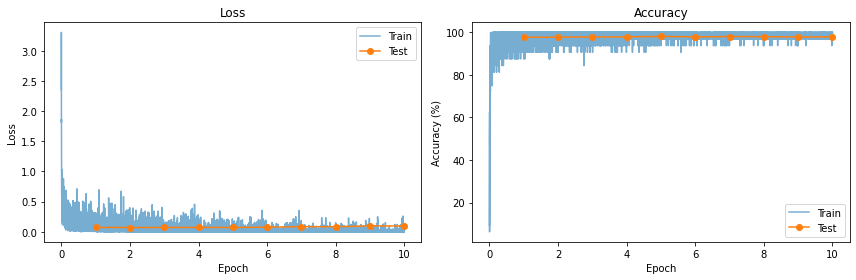

Accuracy: 97 %


In [11]:
# 2e-3
input_size = 28*28
num_classes = 10
lr = 2e-3 #same as 2-layer, except change learning rate
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Learning rate = {lr}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device) #trains for 10 epcos and prints summary line per epoch
plot_learning_curve(train_losses, train_accs, test_losses, test_accs) #draws loss and accuracy curves
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device) #prints final test accuracy

Learning rate = 0.0003
Epoch 1/10 | Train loss: 0.3051, acc: 91.52% | Test loss: 0.1721, acc: 95.34% | Time: 5.3s
Epoch 2/10 | Train loss: 0.1367, acc: 96.20% | Test loss: 0.1135, acc: 96.79% | Time: 5.3s
Epoch 3/10 | Train loss: 0.0928, acc: 97.50% | Test loss: 0.0877, acc: 97.29% | Time: 5.3s
Epoch 4/10 | Train loss: 0.0718, acc: 97.99% | Test loss: 0.0729, acc: 97.81% | Time: 5.3s
Epoch 5/10 | Train loss: 0.0583, acc: 98.35% | Test loss: 0.0699, acc: 97.86% | Time: 5.3s
Epoch 6/10 | Train loss: 0.0487, acc: 98.65% | Test loss: 0.0600, acc: 98.09% | Time: 5.3s
Epoch 7/10 | Train loss: 0.0415, acc: 98.86% | Test loss: 0.0622, acc: 98.05% | Time: 5.3s
Epoch 8/10 | Train loss: 0.0353, acc: 98.97% | Test loss: 0.0593, acc: 98.06% | Time: 5.3s
Epoch 9/10 | Train loss: 0.0311, acc: 99.13% | Test loss: 0.0597, acc: 98.01% | Time: 5.3s
Epoch 10/10 | Train loss: 0.0269, acc: 99.22% | Test loss: 0.0612, acc: 98.18% | Time: 5.3s


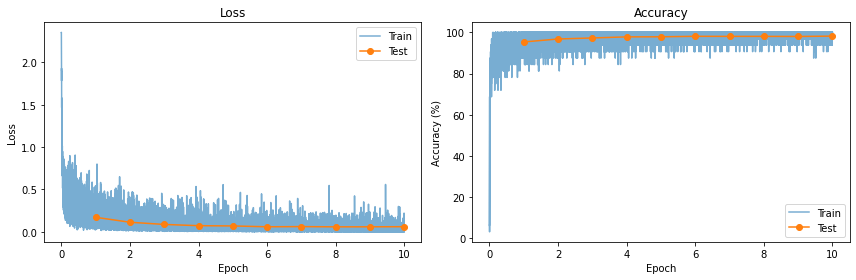

Accuracy: 98 %


In [12]:
# 3e-4
input_size = 28*28
num_classes = 10
lr = 3e-4 #same as before, but different learning rate
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Learning rate = {lr}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)

Learning rate = 0.05
Epoch 1/10 | Train loss: 2.4096, acc: 10.36% | Test loss: 2.3059, acc: 10.28% | Time: 6.2s
Epoch 2/10 | Train loss: 2.3077, acc: 10.59% | Test loss: 2.3075, acc: 9.80% | Time: 6.5s
Epoch 3/10 | Train loss: 2.3076, acc: 10.37% | Test loss: 2.3121, acc: 9.74% | Time: 6.5s
Epoch 4/10 | Train loss: 2.3083, acc: 10.56% | Test loss: 2.3099, acc: 10.10% | Time: 6.5s
Epoch 5/10 | Train loss: 2.3081, acc: 10.46% | Test loss: 2.3071, acc: 11.35% | Time: 6.5s
Epoch 6/10 | Train loss: 2.3077, acc: 10.65% | Test loss: 2.3048, acc: 10.10% | Time: 6.5s
Epoch 7/10 | Train loss: 2.3075, acc: 10.56% | Test loss: 2.3080, acc: 10.10% | Time: 6.5s
Epoch 8/10 | Train loss: 2.3079, acc: 10.43% | Test loss: 2.3078, acc: 10.28% | Time: 6.5s
Epoch 9/10 | Train loss: 2.3072, acc: 10.42% | Test loss: 2.3058, acc: 11.35% | Time: 6.5s
Epoch 10/10 | Train loss: 2.3082, acc: 10.37% | Test loss: 2.3017, acc: 11.35% | Time: 6.5s


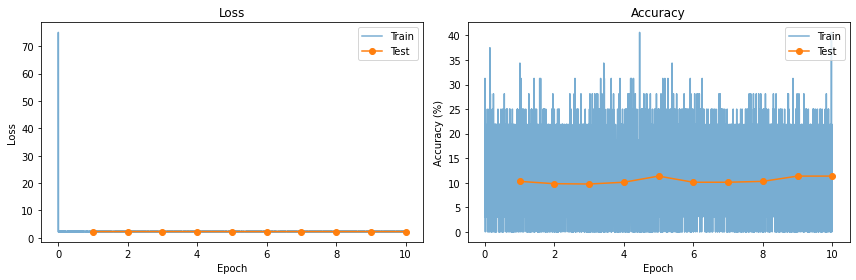

Accuracy: 11 %


In [13]:
# 5e-2
input_size = 28*28
num_classes = 10
lr = 5e-2
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Learning rate = {lr}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size, device=device)

### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

ANSWER HERE

For lr = 2e-3, training well. Training loss drops very fast in first and second epoch then plateaus. Test accuracy goes very high(around 98%), and remains close to train accuracy. The train and test curves track each other, so there isn't enough underfitting or overfitting to be concerned about. If test loss increases in later epochs while train loss decreases, that would be mild overfitting.

For lr = 3e-4, training well, but slower than lr = 2e-3. The curves are smoother and have less noise on each iteration. Loss decreases slower than 2e-3, and test accuracy is similar or slightly better at the end. The model is not underfitting normally, because the accuracy remains high. If the curves contiune to improve significantly at epoch 10, it's slightly under-trained.

For lr = 5e-2, it's unstable and training poorly. The loss has to be high, noisy, with spikes, and accuracy is much lower than other two runs. In worst case, loss stays ~2.3 and accuracy ~10%, indicating that model isn't learning. It's not overfitting because the train accuracy is also low. This is a clear failure to optimize, and looks like underfitting even though model has enough capacity. Cause of failure is not architecture, but instead the learning rate.


### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Optimizer: SGD
Epoch 1/10 | Train loss: 0.6882, acc: 84.36% | Test loss: 0.3570, acc: 90.14% | Time: 4.9s
Epoch 2/10 | Train loss: 0.3456, acc: 90.11% | Test loss: 0.3078, acc: 91.44% | Time: 4.9s
Epoch 3/10 | Train loss: 0.3139, acc: 91.01% | Test loss: 0.2924, acc: 91.66% | Time: 4.9s
Epoch 4/10 | Train loss: 0.2975, acc: 91.50% | Test loss: 0.2767, acc: 92.31% | Time: 4.9s
Epoch 5/10 | Train loss: 0.2865, acc: 91.81% | Test loss: 0.2696, acc: 92.49% | Time: 4.9s
Epoch 6/10 | Train loss: 0.2771, acc: 92.10% | Test loss: 0.2623, acc: 92.57% | Time: 4.9s
Epoch 7/10 | Train loss: 0.2698, acc: 92.41% | Test loss: 0.2590, acc: 92.61% | Time: 4.9s
Epoch 8/10 | Train loss: 0.2628, acc: 92.56% | Test loss: 0.2510, acc: 93.00% | Time: 4.9s
Epoch 9/10 | Train loss: 0.2560, acc: 92.79% | Test loss: 0.2443, acc: 93.16% | Time: 4.9s
Epoch 10/10 | Train loss: 0.2496, acc: 93.03% | Test loss: 0.2384, acc: 93.30% | Time: 4.9s


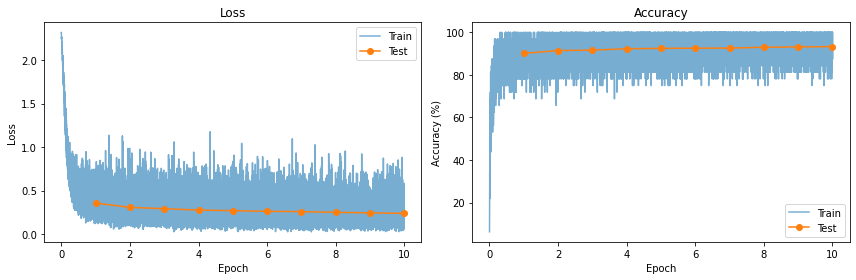

Accuracy: 93 %


In [14]:
# SGD
input_size = 28*28
num_classes = 10
lr = 2e-3 #chooses best lr from last section
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr) #uses SGD optimizer

print('Optimizer: SGD')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Optimizer: SGD, momentum = 0.5
Epoch 1/10 | Train loss: 0.5353, acc: 85.97% | Test loss: 0.3243, acc: 90.66% | Time: 5.0s
Epoch 2/10 | Train loss: 0.3201, acc: 90.72% | Test loss: 0.2879, acc: 91.72% | Time: 5.0s
Epoch 3/10 | Train loss: 0.2978, acc: 91.49% | Test loss: 0.2737, acc: 92.31% | Time: 5.0s
Epoch 4/10 | Train loss: 0.2834, acc: 91.90% | Test loss: 0.2739, acc: 92.43% | Time: 5.0s
Epoch 5/10 | Train loss: 0.2719, acc: 92.28% | Test loss: 0.2588, acc: 92.72% | Time: 5.0s
Epoch 6/10 | Train loss: 0.2612, acc: 92.67% | Test loss: 0.2437, acc: 93.22% | Time: 5.0s
Epoch 7/10 | Train loss: 0.2497, acc: 93.04% | Test loss: 0.2423, acc: 92.98% | Time: 5.0s
Epoch 8/10 | Train loss: 0.2381, acc: 93.33% | Test loss: 0.2301, acc: 93.51% | Time: 5.0s
Epoch 9/10 | Train loss: 0.2257, acc: 93.80% | Test loss: 0.2220, acc: 93.85% | Time: 5.0s
Epoch 10/10 | Train loss: 0.2123, acc: 94.16% | Test loss: 0.2059, acc: 94.34% | Time: 5.0s


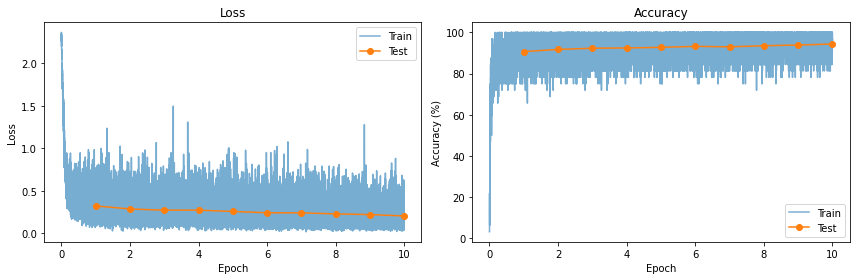

Accuracy: 94 %


In [15]:
# SGD 0.5
input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.5) #same as before, different momentum

print('Optimizer: SGD, momentum = 0.5')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Optimizer: SGD, momentum = 0.9
Epoch 1/10 | Train loss: 0.3749, acc: 89.17% | Test loss: 0.2621, acc: 92.50% | Time: 5.1s
Epoch 2/10 | Train loss: 0.2418, acc: 93.17% | Test loss: 0.2019, acc: 94.52% | Time: 5.1s
Epoch 3/10 | Train loss: 0.1742, acc: 95.23% | Test loss: 0.1440, acc: 96.03% | Time: 5.0s
Epoch 4/10 | Train loss: 0.1294, acc: 96.48% | Test loss: 0.1137, acc: 96.77% | Time: 5.0s
Epoch 5/10 | Train loss: 0.1044, acc: 97.17% | Test loss: 0.0991, acc: 97.12% | Time: 5.0s
Epoch 6/10 | Train loss: 0.0881, acc: 97.61% | Test loss: 0.0847, acc: 97.56% | Time: 5.0s
Epoch 7/10 | Train loss: 0.0767, acc: 97.88% | Test loss: 0.0805, acc: 97.58% | Time: 5.0s
Epoch 8/10 | Train loss: 0.0686, acc: 98.12% | Test loss: 0.0724, acc: 97.85% | Time: 5.0s
Epoch 9/10 | Train loss: 0.0622, acc: 98.27% | Test loss: 0.0671, acc: 98.03% | Time: 5.0s
Epoch 10/10 | Train loss: 0.0567, acc: 98.43% | Test loss: 0.0689, acc: 97.82% | Time: 5.0s


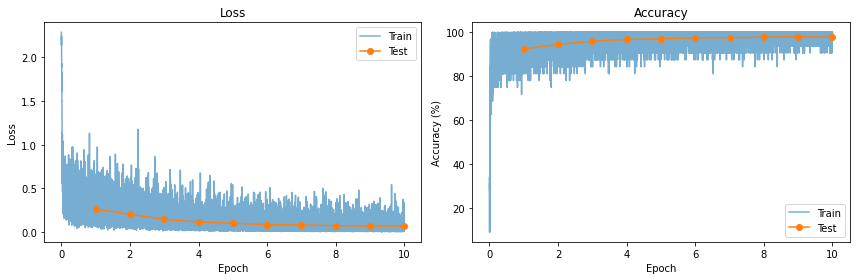

Accuracy: 97 %


In [16]:
# SGD 0.9
input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9) #same as before, with new momentum

print('Optimizer: SGD, momentum = 0.9')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

ANSWER HERE

Plain SGD updates each weight using the same step w <- w - lr x gradient. Only uses the current mini-batch gradient, so updates are cautious and noisy with a small learning rate.
SGD with momentum keeps a constantly updating average of past gradients. Gradients that point in similar directions build up speed, and if it oscillates it partially cancels out.
Adam combines momentum with per-parameter adaptive step size, dividing by the running average of squared gradient, so each weight gets better at their own learning rate. 

Plain SGD was the slowest of all the optimzations, having 89.93% accuracy at Epoch 1, while all other had at least 91% accuracy. But test loss continued to fall, ever at Epoch 10, being at 0.2555. The model is under-trained because train adn test accuracy are basically didentical. It needs more epochs.

Momentum 0.5 was significantly better than plain SGD at each epoch, ending with 94.4% with less loss. The curve shape is very similar, only a bit steeper. It also continues to improve even at epoch 10.

Momentum 0.9 was the best SGD variant by far. Test accuracy went from 92.2 to 98%, and test loss dropped to 0.0655, much lower than all the other models. The curves flattened around epochs 7-10, and the effective step is 10x larger and converged significantly faster. Train and test curves remain close, no sign of overfitting and curve is just as stable as others.

Adam was fastest initially, with 97% test accuracy after the first epoch and reached 99.4% accuracy in the late epochs. Test loss rose from 0.0863 to 0.2114 while test accuracy stayed around 97%, a clear sign of overfitting.


### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

Initialization: zeros
Epoch 1/10 | Train loss: 2.3014, acc: 11.16% | Test loss: 2.3013, acc: 11.35% | Time: 7.4s
Epoch 2/10 | Train loss: 2.3016, acc: 11.24% | Test loss: 2.3012, acc: 11.35% | Time: 7.5s
Epoch 3/10 | Train loss: 2.3016, acc: 11.24% | Test loss: 2.3012, acc: 11.35% | Time: 7.2s
Epoch 4/10 | Train loss: 2.3015, acc: 11.24% | Test loss: 2.3013, acc: 11.35% | Time: 7.1s
Epoch 5/10 | Train loss: 2.3014, acc: 11.24% | Test loss: 2.3013, acc: 11.35% | Time: 7.2s
Epoch 6/10 | Train loss: 2.3015, acc: 11.24% | Test loss: 2.3014, acc: 11.35% | Time: 7.3s
Epoch 7/10 | Train loss: 2.3015, acc: 11.20% | Test loss: 2.3013, acc: 11.35% | Time: 7.4s
Epoch 8/10 | Train loss: 2.3015, acc: 11.22% | Test loss: 2.3011, acc: 11.35% | Time: 7.1s
Epoch 9/10 | Train loss: 2.3015, acc: 11.24% | Test loss: 2.3013, acc: 11.35% | Time: 7.4s
Epoch 10/10 | Train loss: 2.3015, acc: 11.24% | Test loss: 2.3011, acc: 11.35% | Time: 7.3s


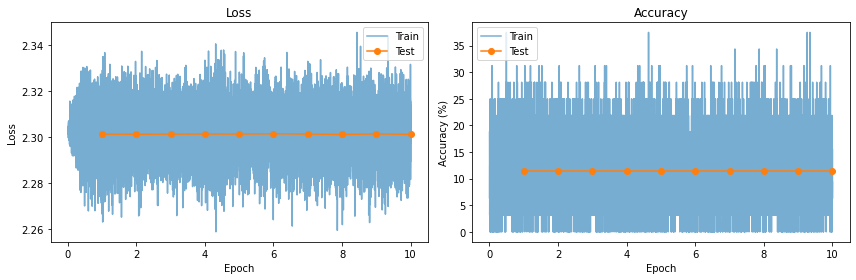

Accuracy: 11 %


In [17]:
# All zeros
input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
for p in net.parameters():
    nn.init.zeros_(p) #initialize weights to all zeros
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print('Initialization: zeros')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Initialization: ones
Epoch 1/10 | Train loss: 1.6104, acc: 86.53% | Test loss: 0.2980, acc: 91.51% | Time: 5.5s
Epoch 2/10 | Train loss: 0.3116, acc: 91.22% | Test loss: 0.3128, acc: 91.24% | Time: 5.3s
Epoch 3/10 | Train loss: 0.3089, acc: 91.24% | Test loss: 0.2974, acc: 91.44% | Time: 5.3s
Epoch 4/10 | Train loss: 0.2946, acc: 91.64% | Test loss: 0.2843, acc: 92.11% | Time: 5.3s
Epoch 5/10 | Train loss: 0.2870, acc: 91.78% | Test loss: 0.2791, acc: 92.18% | Time: 5.3s
Epoch 6/10 | Train loss: 0.2786, acc: 92.05% | Test loss: 0.2707, acc: 92.13% | Time: 5.4s
Epoch 7/10 | Train loss: 0.2703, acc: 92.32% | Test loss: 0.2645, acc: 92.46% | Time: 5.4s
Epoch 8/10 | Train loss: 0.2633, acc: 92.55% | Test loss: 0.2875, acc: 91.79% | Time: 5.4s
Epoch 9/10 | Train loss: 0.2591, acc: 92.58% | Test loss: 0.2703, acc: 92.53% | Time: 5.4s
Epoch 10/10 | Train loss: 0.2506, acc: 92.91% | Test loss: 0.2647, acc: 92.63% | Time: 5.4s


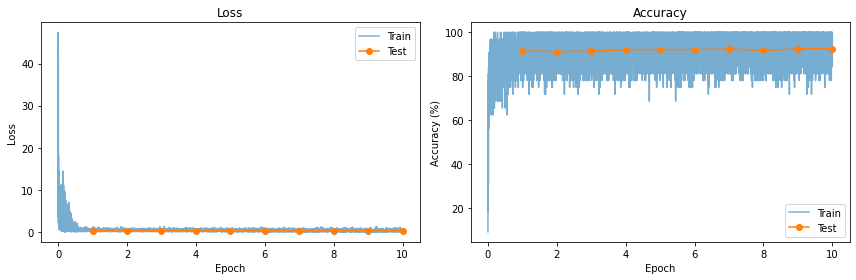

Accuracy: 92 %


In [18]:
# All ones
input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
for p in net.parameters():
    nn.init.ones_(p) #initialize weights to All ones
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print('Initialization: ones')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Initialization: Random (mean 0, std 0.01)
Epoch 1/10 | Train loss: 0.2124, acc: 93.80% | Test loss: 0.1042, acc: 96.90% | Time: 5.5s
Epoch 2/10 | Train loss: 0.0842, acc: 97.45% | Test loss: 0.0706, acc: 97.91% | Time: 5.5s
Epoch 3/10 | Train loss: 0.0600, acc: 98.19% | Test loss: 0.0694, acc: 97.82% | Time: 5.6s
Epoch 4/10 | Train loss: 0.0456, acc: 98.58% | Test loss: 0.0730, acc: 97.94% | Time: 5.6s
Epoch 5/10 | Train loss: 0.0351, acc: 98.88% | Test loss: 0.0722, acc: 97.89% | Time: 5.7s
Epoch 6/10 | Train loss: 0.0273, acc: 99.11% | Test loss: 0.0727, acc: 98.01% | Time: 5.7s
Epoch 7/10 | Train loss: 0.0219, acc: 99.28% | Test loss: 0.0892, acc: 97.81% | Time: 5.7s
Epoch 8/10 | Train loss: 0.0162, acc: 99.45% | Test loss: 0.0893, acc: 97.84% | Time: 5.7s
Epoch 9/10 | Train loss: 0.0139, acc: 99.54% | Test loss: 0.0887, acc: 97.89% | Time: 5.7s
Epoch 10/10 | Train loss: 0.0123, acc: 99.60% | Test loss: 0.0925, acc: 97.94% | Time: 5.7s


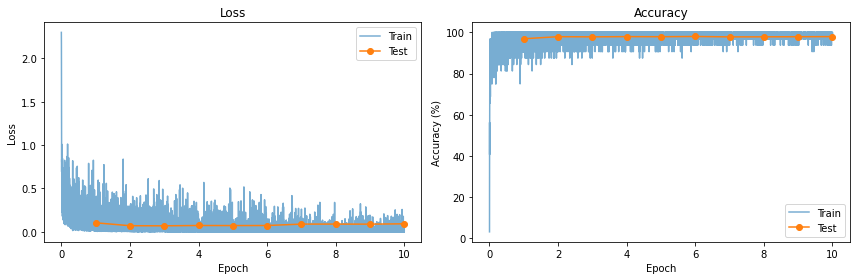

Accuracy: 97 %


In [19]:
# Random
input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
for p in net.parameters():
    nn.init.normal_(p, mean=0.0, std=0.01)#initialize weights randomly
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print('Initialization: Random (mean 0, std 0.01)')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

ANSWER HERE

Initialization strongly affected training. For the zeroes, the netork didn't learn at all. The loss stayed at 2.3, and the accuracy was about 11% for all epochs. Using zero weights, each ReLU output is 0, so the FC weights get 0 gradient, and the conv weights get 0 gradient because of the FC weights. Only the bias can update, so the model just ends up predicting most common class.

The ones network learned, but not as well as I expected. The first epochs had large loss, but as training stabilized accuracy only reached 92.6%. All 20 conv filters begin identical and receive identical gradients, so they remain identical and the conv layer is acting like a singular filter, limiting what the model can learn. 

The random network trained best. The loss began at 2.3 and dropped quickly, reaching 96.9% test accuracy after a single epoch and roughly 98% near the end. Random values broke the symmetry, so every filter and neuron learns something new. Test loss did rise slightly after epoch 3 while train accuracy kept increasing, which could be a sign of overfitting.

Expected: In theory, all-ones shoudl fail like zeros, because identical weights should give identical neurons. Out result ended up being much better than that, but was still significantly worse than random initialization.

Recommendation: We could initialize weights randomly with smaller values scaled to the layer size with biases set to 0. Random values have been shown to break symmetry so units learn different features, and scalign by layer size keeps activations and gradients from vanishing(as seen with zeroes) or exploding(as seen with 1's.

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Activation: tanh
Epoch 1/10 | Train loss: 0.3750, acc: 89.30% | Test loss: 0.3298, acc: 89.96% | Time: 6.1s
Epoch 2/10 | Train loss: 0.2716, acc: 92.27% | Test loss: 0.2011, acc: 94.55% | Time: 6.0s
Epoch 3/10 | Train loss: 0.1819, acc: 94.75% | Test loss: 0.1615, acc: 95.32% | Time: 6.6s
Epoch 4/10 | Train loss: 0.1368, acc: 95.96% | Test loss: 0.1368, acc: 95.99% | Time: 6.4s
Epoch 5/10 | Train loss: 0.1157, acc: 96.48% | Test loss: 0.1254, acc: 96.11% | Time: 6.6s
Epoch 6/10 | Train loss: 0.1072, acc: 96.68% | Test loss: 0.1366, acc: 95.94% | Time: 6.4s
Epoch 7/10 | Train loss: 0.0964, acc: 97.06% | Test loss: 0.1215, acc: 96.53% | Time: 6.2s
Epoch 8/10 | Train loss: 0.0889, acc: 97.28% | Test loss: 0.1200, acc: 96.54% | Time: 6.1s
Epoch 9/10 | Train loss: 0.0858, acc: 97.27% | Test loss: 0.1499, acc: 95.98% | Time: 6.4s
Epoch 10/10 | Train loss: 0.0802, acc: 97.54% | Test loss: 0.1428, acc: 96.12% | Time: 5.9s


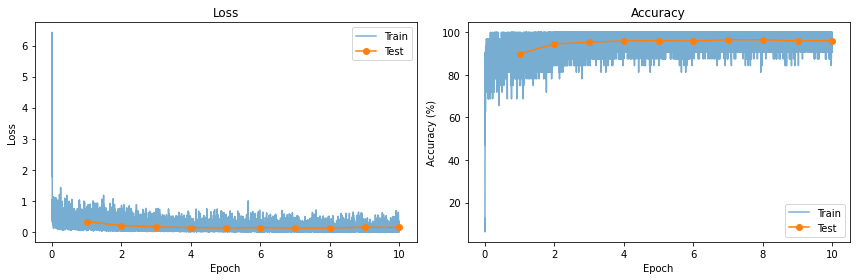

Accuracy: 96 %


In [30]:
class Net2Tanh(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net2Tanh, self).__init__()
        self.conv1 = nn.Conv2d(1, 20, kernel_size=3, stride=1) #2D convolutional layer creation
        self.tanh = nn.Tanh() # creates Tanh activation function
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes) #calculates # of input features

    def forward(self, x):
        x = x.view(-1, 1, 28, 28) #reshape input images
        out = self.conv1(x)
        out = self.tanh(out) 
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        return out

input_size = 28*28
num_classes = 10
lr = 2e-3 # use the same lr/optimizer as your best earlier run
num_epochs = 10

net = Net2Tanh(input_size, num_classes) 
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss() #create loss function to measure prediction errors
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print('Activation: tanh')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

ANSWER HERE

Changing ReLU to tanh made performance slightly worse, tanh trained more slowly and reached a lower accuracy. After one epoch ReLU already had 97.7% test accuracy, while tanh had about 90%. Tanh's first epochs also had a larger loss spike(6.4 vs 3.3 ReLU). Tanh also had a slower fitting of training data. After 10 epochs, ReLU's train loss was about 0.0059, while tanh was at 0.0802, roughly 14 times higher. ReLU also had 99.8% train accuracy while tanh only at 97.54%. 
Tanh did worse because of saturations and small gradients. Tanh squishes outputs into (-1,1) and for bigger positive or negative inputs the slope is really close to 0. Saturated units pass back nearly no gradients, so learning is much slower. ReLU has a gradient of 1 for all positive inputs, so this is the big difference. PyTorch's base initialization also favors ReLU-type networks. Tanh usually runs much more efficiently with Xavier initialization, so this could have been another factor that contributed to Tanh's performance.

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Batch size: 8
Epoch 1/10 | Train loss: 0.1445, acc: 95.66% | Test loss: 0.0728, acc: 97.81% | Time: 12.9s
Epoch 2/10 | Train loss: 0.0633, acc: 98.05% | Test loss: 0.0678, acc: 97.94% | Time: 13.2s
Epoch 3/10 | Train loss: 0.0420, acc: 98.65% | Test loss: 0.0675, acc: 97.93% | Time: 13.3s
Epoch 4/10 | Train loss: 0.0271, acc: 99.14% | Test loss: 0.0739, acc: 98.05% | Time: 13.3s
Epoch 5/10 | Train loss: 0.0184, acc: 99.38% | Test loss: 0.0821, acc: 97.86% | Time: 13.4s
Epoch 6/10 | Train loss: 0.0136, acc: 99.52% | Test loss: 0.0940, acc: 97.88% | Time: 13.9s
Epoch 7/10 | Train loss: 0.0098, acc: 99.68% | Test loss: 0.1074, acc: 97.86% | Time: 14.4s
Epoch 8/10 | Train loss: 0.0069, acc: 99.79% | Test loss: 0.1192, acc: 97.90% | Time: 14.8s
Epoch 9/10 | Train loss: 0.0058, acc: 99.80% | Test loss: 0.1253, acc: 98.05% | Time: 15.3s
Epoch 10/10 | Train loss: 0.0043, acc: 99.85% | Test loss: 0.1316, acc: 97.92% | Time: 15.9s


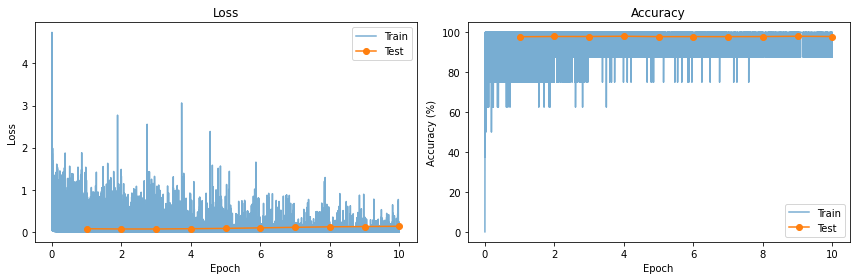

Accuracy: 97 %


In [31]:
# Batch size 8
batch_size = 8 #keep everything from before, but load in with batch_size
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True) #change train and test loader to load in the new batch_size
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Batch size: {batch_size}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Batch size: 64
Epoch 1/10 | Train loss: 0.1815, acc: 94.68% | Test loss: 0.0778, acc: 97.60% | Time: 4.5s
Epoch 2/10 | Train loss: 0.0678, acc: 97.95% | Test loss: 0.0703, acc: 97.79% | Time: 4.5s
Epoch 3/10 | Train loss: 0.0467, acc: 98.52% | Test loss: 0.0666, acc: 97.92% | Time: 4.3s
Epoch 4/10 | Train loss: 0.0339, acc: 98.93% | Test loss: 0.0613, acc: 98.04% | Time: 4.4s
Epoch 5/10 | Train loss: 0.0255, acc: 99.18% | Test loss: 0.0700, acc: 97.90% | Time: 4.4s
Epoch 6/10 | Train loss: 0.0189, acc: 99.41% | Test loss: 0.0630, acc: 98.13% | Time: 4.5s
Epoch 7/10 | Train loss: 0.0151, acc: 99.55% | Test loss: 0.0714, acc: 98.00% | Time: 4.4s
Epoch 8/10 | Train loss: 0.0102, acc: 99.70% | Test loss: 0.0756, acc: 98.04% | Time: 4.4s
Epoch 9/10 | Train loss: 0.0100, acc: 99.71% | Test loss: 0.0763, acc: 98.03% | Time: 4.5s
Epoch 10/10 | Train loss: 0.0082, acc: 99.75% | Test loss: 0.0775, acc: 98.13% | Time: 4.4s


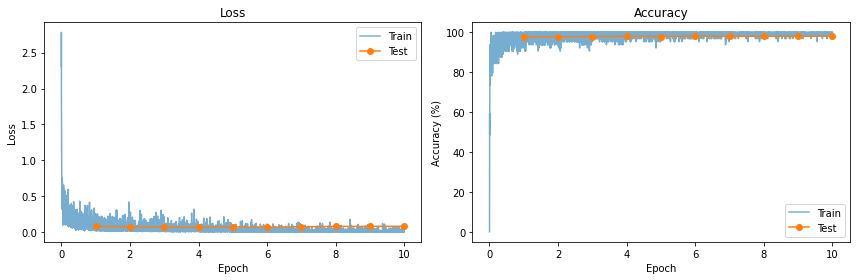

Accuracy: 98 %


In [32]:
# Batch size 64
batch_size = 64 #same as before but batch size is 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Batch size: {batch_size}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Batch size: 128
Epoch 1/10 | Train loss: 0.2350, acc: 92.97% | Test loss: 0.0931, acc: 97.27% | Time: 4.4s
Epoch 2/10 | Train loss: 0.0803, acc: 97.65% | Test loss: 0.0644, acc: 98.08% | Time: 4.1s
Epoch 3/10 | Train loss: 0.0528, acc: 98.39% | Test loss: 0.0636, acc: 98.06% | Time: 4.1s
Epoch 4/10 | Train loss: 0.0388, acc: 98.83% | Test loss: 0.0608, acc: 98.03% | Time: 4.1s
Epoch 5/10 | Train loss: 0.0295, acc: 99.10% | Test loss: 0.0617, acc: 98.27% | Time: 4.1s
Epoch 6/10 | Train loss: 0.0231, acc: 99.33% | Test loss: 0.0606, acc: 98.24% | Time: 4.1s
Epoch 7/10 | Train loss: 0.0182, acc: 99.46% | Test loss: 0.0661, acc: 98.26% | Time: 4.1s
Epoch 8/10 | Train loss: 0.0143, acc: 99.60% | Test loss: 0.0761, acc: 97.89% | Time: 4.1s
Epoch 9/10 | Train loss: 0.0123, acc: 99.65% | Test loss: 0.0703, acc: 98.13% | Time: 4.1s
Epoch 10/10 | Train loss: 0.0093, acc: 99.75% | Test loss: 0.0738, acc: 98.02% | Time: 4.1s


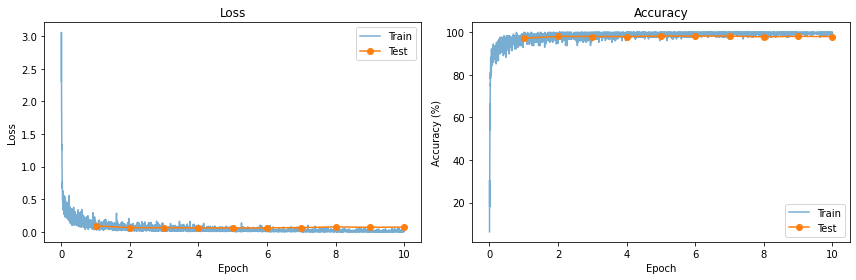

Accuracy: 98 %


In [33]:
# Batch size 128
batch_size = 128 #same as before but with batch size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
lr = 2e-3
num_epochs = 10

net = Net2(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

print(f'Batch size: {batch_size}')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

ANSWER HERE

Batch size 8 made 16x more updates per epoch than 128, so it fit the training data fastest. Epoch 1 train loss was 0.1445(0.1815 for 64 and 0.235 for 128), and its epoch 10 train loss was 0.0043(0.0082 for 64 and 0.0093 for 128). The larger batches took fewer larger sample steps, so they were slightly behind at each epoch. 

The training loss curve at batch size 8 is very jagged, spiking up to about 3-4 even late in training, and its train accuracy per iteration jumps in steps. The curves ends up being smoother at 64 and smoothest at 128, because each gradient averages more examples.

So smaller batches give more updates per epoch, noisier gradients, faster fitting of the training set and slower epochs. In our runs this didn't improve test accuracy and instead increased overfitting. Larger batches give smoother training but makes less updates per epoch, so their converge slower per epoch. 

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [37]:
# Define 5-Layer Network
class Net5(nn.Module):
    def __init__(self, input_size=1, num_classes=10):
        super(Net5, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2) #first conv layer
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) #pooling layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2) #second conv layer
        self.fc1 = nn.Linear(64 * 14 * 14, 1024) #last 2 fully connected layers
        self.fc2 = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = x.view(-1, 1, 28, 28) #reshape input images
        out = self.pool(self.relu(self.conv1(x))) #passes input through layers, applying ReLU and max pooling
        out = self.relu(self.conv2(out))
        out = out.view(out.size(0), -1) #flatten output into one-dimensional vector 
        out = self.relu(self.fc1(out))#apply ReLU and passes the 12,544 features through fc layer
        out = self.fc2(out)
        return out

# ...

#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [38]:
# Define FCN
class FCN(nn.Module):
    def __init__(self, input_size=784, num_classes=10):
        super(FCN, self).__init__()
        self.fc1 = nn.Linear(input_size, 256) #layer 1
        self.relu = nn.ReLU() #all negative values --> 0
        self.fc2 = nn.Linear(256, 256) #layer 2
        self.fc3 = nn.Linear(256, num_classes) # layer 3

    def forward(self, x):
        x = x.view(x.size(0), -1) 
        out = self.relu(self.fc1(x)) #passes flattened input through fc1
        out = self.relu(self.fc2(out)) #passes through fc2
        out = self.fc3(out) #and fc3
        return out

# ...

#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


Model: Net2
Epoch 1/10 | Train loss: 0.2041, acc: 93.94% | Test loss: 0.0846, acc: 97.28% | Time: 4.4s
Epoch 2/10 | Train loss: 0.0765, acc: 97.73% | Test loss: 0.0716, acc: 97.75% | Time: 4.4s
Epoch 3/10 | Train loss: 0.0541, acc: 98.38% | Test loss: 0.0643, acc: 98.04% | Time: 4.4s
Epoch 4/10 | Train loss: 0.0402, acc: 98.79% | Test loss: 0.0586, acc: 98.22% | Time: 4.4s
Epoch 5/10 | Train loss: 0.0309, acc: 99.05% | Test loss: 0.0670, acc: 98.03% | Time: 4.4s
Epoch 6/10 | Train loss: 0.0248, acc: 99.20% | Test loss: 0.0659, acc: 97.99% | Time: 4.4s
Epoch 7/10 | Train loss: 0.0190, acc: 99.38% | Test loss: 0.0663, acc: 98.14% | Time: 4.4s
Epoch 8/10 | Train loss: 0.0146, acc: 99.56% | Test loss: 0.0734, acc: 98.09% | Time: 4.4s
Epoch 9/10 | Train loss: 0.0124, acc: 99.60% | Test loss: 0.0701, acc: 98.12% | Time: 4.4s
Epoch 10/10 | Train loss: 0.0105, acc: 99.66% | Test loss: 0.0792, acc: 98.05% | Time: 4.4s


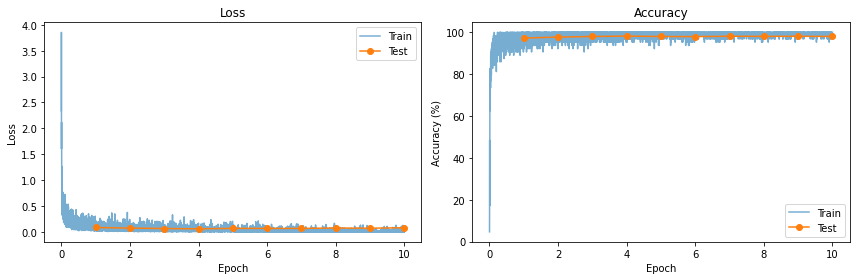

Accuracy: 98 %


In [39]:
# Net2
batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
num_epochs = 10
lr = 2e-3 
use_sgd_momentum = False # false=Adam, True=SGD with momentum 0.9

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
loss_function = nn.CrossEntropyLoss()

def make_optimizer(model):
    if use_sgd_momentum:
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    return torch.optim.Adam(model.parameters(), lr=lr)

net = Net2(input_size, num_classes)#Net2 here
net.to(device)
optimizer = make_optimizer(net)

print('Model: Net2')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Model: Net5
Epoch 1/10 | Train loss: 0.1697, acc: 94.80% | Test loss: 0.0946, acc: 96.94% | Time: 49.9s
Epoch 2/10 | Train loss: 0.0555, acc: 98.26% | Test loss: 0.0473, acc: 98.57% | Time: 52.1s
Epoch 3/10 | Train loss: 0.0400, acc: 98.74% | Test loss: 0.0435, acc: 98.54% | Time: 52.0s
Epoch 4/10 | Train loss: 0.0301, acc: 99.03% | Test loss: 0.0380, acc: 98.84% | Time: 52.0s
Epoch 5/10 | Train loss: 0.0235, acc: 99.24% | Test loss: 0.0498, acc: 98.52% | Time: 52.1s
Epoch 6/10 | Train loss: 0.0208, acc: 99.35% | Test loss: 0.0379, acc: 98.85% | Time: 52.0s
Epoch 7/10 | Train loss: 0.0160, acc: 99.48% | Test loss: 0.0440, acc: 98.91% | Time: 52.6s
Epoch 8/10 | Train loss: 0.0153, acc: 99.55% | Test loss: 0.0482, acc: 98.71% | Time: 52.1s
Epoch 9/10 | Train loss: 0.0143, acc: 99.58% | Test loss: 0.0555, acc: 98.72% | Time: 52.7s
Epoch 10/10 | Train loss: 0.0118, acc: 99.65% | Test loss: 0.0524, acc: 98.79% | Time: 52.4s


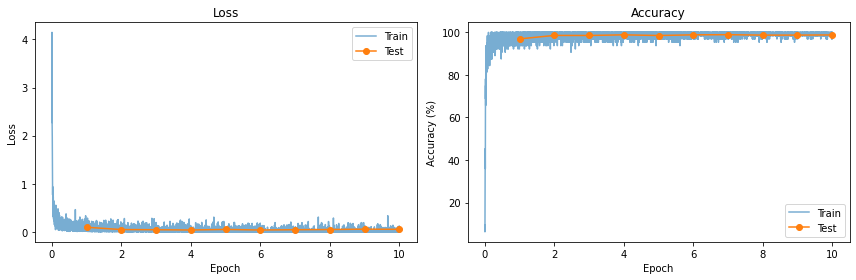

Accuracy: 98 %


In [40]:
# Net5
batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
num_epochs = 10
lr = 2e-3
use_sgd_momentum = False  

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
loss_function = nn.CrossEntropyLoss()

def make_optimizer(model):
    if use_sgd_momentum:
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    return torch.optim.Adam(model.parameters(), lr=lr)

net = Net5(input_size, num_classes) #same as before but with Net5
net.to(device)
optimizer = make_optimizer(net)

print('Model: Net5')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

Model: FCN
Epoch 1/10 | Train loss: 0.2227, acc: 93.27% | Test loss: 0.1146, acc: 96.28% | Time: 5.9s
Epoch 2/10 | Train loss: 0.0906, acc: 97.16% | Test loss: 0.0907, acc: 97.21% | Time: 6.1s
Epoch 3/10 | Train loss: 0.0641, acc: 98.00% | Test loss: 0.0865, acc: 97.47% | Time: 5.9s
Epoch 4/10 | Train loss: 0.0491, acc: 98.45% | Test loss: 0.0920, acc: 97.34% | Time: 6.0s
Epoch 5/10 | Train loss: 0.0393, acc: 98.77% | Test loss: 0.0918, acc: 97.44% | Time: 6.0s
Epoch 6/10 | Train loss: 0.0336, acc: 98.91% | Test loss: 0.1241, acc: 97.33% | Time: 5.9s
Epoch 7/10 | Train loss: 0.0307, acc: 98.99% | Test loss: 0.1119, acc: 97.53% | Time: 5.9s
Epoch 8/10 | Train loss: 0.0273, acc: 99.12% | Test loss: 0.0913, acc: 97.87% | Time: 6.0s
Epoch 9/10 | Train loss: 0.0231, acc: 99.25% | Test loss: 0.1411, acc: 97.27% | Time: 6.0s
Epoch 10/10 | Train loss: 0.0232, acc: 99.29% | Test loss: 0.1076, acc: 97.71% | Time: 6.1s


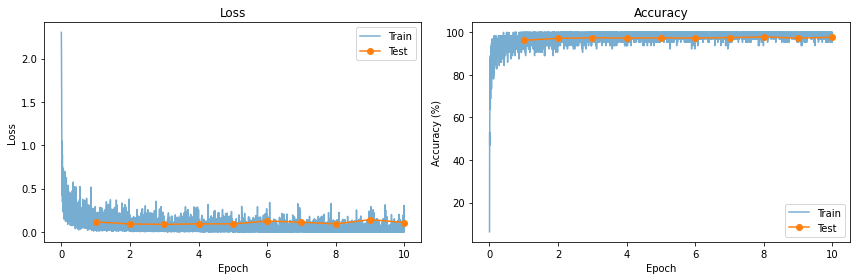

Accuracy: 97 %


In [41]:
# FCN
# Net5
batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)

input_size = 28*28
num_classes = 10
num_epochs = 10
lr = 2e-3     
use_sgd_momentum = False 

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
loss_function = nn.CrossEntropyLoss()

def make_optimizer(model):
    if use_sgd_momentum:
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    return torch.optim.Adam(model.parameters(), lr=lr)

net = FCN(input_size, num_classes)#same as before but with FCN
net.to(device)
optimizer = make_optimizer(net)

print('Model: FCN')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

Net5 is the best model. It had the highest test accuracy(98.79% at epoch 10) and the lowest test loss(0.0524), compared to Net2(98.05%, 0.0792) and FCN(97.71%, 0.1076). Its test loss also remained lower and steadier across all epochs, while FCN's test loss remained noisy across the last epochs(0.0913, 0.1411, 0.1076). The real downside is that Net5 took much more time on each epoch(about 52sec), which is much much longer than Net2's(4.4sec) and FCN's(~6.0sec).

#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

In terms of epcohs, Net2 and FCN were similar at the satart(epoch 1 test accuracy of 97.28% and 96.28%), while Net 5 had its lowest test loss (0.047) by epoch 2 and 98.5% test accuracy by then, much faster than the others. Net5's train loss was also the lowest at epoch 1(0.1697 vs 0.2041 Net2 v 0.2227 FCN). SO Net5 converges in fewest epochs, because of convolutional features are better for images and each update makes more progress/

#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

A pooling layer downsamples each feature map by summarizing smaller regions. THe purpose is to reduce size and computation, reduce overfitting, increase the receptive field, and to enable translation invariance. A 2x2 pool wih stride 2 halves height and width, so 4x fewer activations. This means less parameteres in the layers and faster training. In Net5, pooling reduced feature maps from 28*28 to 14*14 after the first conv layer.

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

It is possible for a model to have a smaller final loss, even if it has worse test accuracy, because loss and accuracy represent two different values. Accuracy only checks whether the highest-scoring class matches, while cross-entropy loss depends on how confident the predicted probabilities are.

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

In FCN, each neuron connects to each input from the previous layer, soa  28 by 28 gets flattened into 784 independent numbers and all spatial structure no longer exists. In CNN, each neuron looks at a small patch(3x3 or 5x5), so neighboring pixels get processed together.

In results, CNNs generalized better(98.05% for Net2, 98.79% for Net5, and 97.7% for FCN) and had lower test loss(0.0792 and 0.0524 vs 0.1076), which was expected for image data. FCN is simpler and trains faster per epoch than Net5, but works worse with images.


---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



Model: Net5 + BatchNorm
Epoch 1/10 | Train loss: 0.0929, acc: 97.12% | Test loss: 0.0488, acc: 98.49% | Time: 50.9s
Epoch 2/10 | Train loss: 0.0401, acc: 98.76% | Test loss: 0.0456, acc: 98.50% | Time: 51.6s
Epoch 3/10 | Train loss: 0.0311, acc: 99.00% | Test loss: 0.0336, acc: 98.89% | Time: 51.3s
Epoch 4/10 | Train loss: 0.0233, acc: 99.27% | Test loss: 0.0287, acc: 99.09% | Time: 51.4s
Epoch 5/10 | Train loss: 0.0199, acc: 99.35% | Test loss: 0.0297, acc: 99.11% | Time: 51.1s
Epoch 6/10 | Train loss: 0.0181, acc: 99.42% | Test loss: 0.0230, acc: 99.30% | Time: 51.0s
Epoch 7/10 | Train loss: 0.0140, acc: 99.52% | Test loss: 0.0389, acc: 98.89% | Time: 52.1s
Epoch 8/10 | Train loss: 0.0118, acc: 99.62% | Test loss: 0.0307, acc: 99.01% | Time: 51.3s
Epoch 9/10 | Train loss: 0.0111, acc: 99.66% | Test loss: 0.0353, acc: 99.13% | Time: 51.3s
Epoch 10/10 | Train loss: 0.0106, acc: 99.66% | Test loss: 0.0317, acc: 99.25% | Time: 51.2s


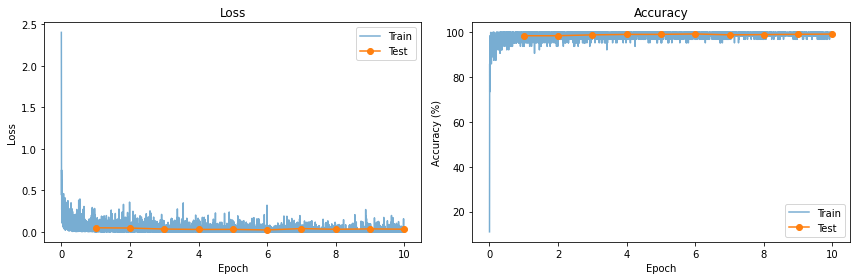

Accuracy: 99 %


In [43]:
class Net5BN(nn.Module):
    def __init__(self, input_size=1, num_classes=10):
        super(Net5BN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2) #conv layer 1
        self.bn1 = nn.BatchNorm2d(32) #batch normalization for 32 feature maps
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # max pooling over 2x2 windows
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2) #conv layer 2
        self.bn2 = nn.BatchNorm2d(64) 
        self.fc1 = nn.Linear(64 * 14 * 14, 1024) #first fc layer, input size 64x14x14
        self.bn3 = nn.BatchNorm1d(1024) #batch norm for fc1
        self.fc2 = nn.Linear(1024, num_classes) #second fc layer

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        out = self.pool(self.relu(self.bn1(self.conv1(x)))) #run through the layers and ReLU
        out = self.relu(self.bn2(self.conv2(out)))
        out = out.view(out.size(0), -1)
        out = self.relu(self.bn3(self.fc1(out)))
        out = self.fc2(out)                  
        return out
net = Net5BN(input_size, num_classes) #run through Net5BN
net.to(device)
optimizer = make_optimizer(net)

print('Model: Net5 + BatchNorm')
train(net, loss_function, optimizer, train_loader, test_loader, batch_size, num_epochs, device)
plot_learning_curve(train_losses, train_accs, test_losses, test_accs)
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

A batch normalization layer normalizes each layer's inputs, using mean and variance of current mini-batch to zero mean and unit variance. After, it applies a learned scale and shift, so network chooses which distribution works the best. It also retains the scale of activations stable between layers, even as weights of earlier layers change during training.

---
---

# End of Phase 1 😊🥳